# AyiQuant EA1 — Trend-Following Strategy Research

### Research Question

Why does EA1 generate positive historical returns but exhibit weak risk-adjusted performance?

### Research Objective

To investigate the historical performance and risk characteristics of an EMA-based trend-following strategy, focusing on its returns, drawdowns, market exposure, and trade-level behavior.

## EA1 v0.1 — Frozen Baseline

**Asset:** QQQ  
**Strategy:** Trend Following  
**Indicators:** EMA20 and EMA50  
**Position:** Long / Flat  
**Data Source:** Yahoo Finance  
**Data Period:** 2021-09-13 to 2026-09-14  
**Adjusted Prices:** Yes (`auto_adjust=True`)           
**Timeframe:** Daily (1D)  
**Execution Assumption:** Positions are shifted by one trading day to avoid look-ahead bias.

### Research Rule

EA1 v0.1 is frozen during this research phase.

No strategy modifications or optimization will be performed.

The purpose of this notebook is to understand the behavior and
performance characteristics of the existing strategy.

In [1]:
import numpy as np
import pandas as pd

from data_loader_EA1 import load_data
from indicators_EA1 import calculate_ema
from signals_EA1 import generate_trend_signal, generate_trade_events


In [2]:
df = load_data("QQQ")

[*********************100%***********************]  1 of 1 completed


In [3]:
df.head()

Price,Close,High,Low,Open,Volume
Ticker,QQQ,QQQ,QQQ,QQQ,QQQ
Date,,,,,
2021-09-13,364.844055,367.849446,362.798468,367.422873,48741800
2021-09-14,363.806641,367.054371,362.856541,366.327262,41826600
2021-09-15,366.511627,366.860655,361.974471,364.262458,34097900
2021-09-16,366.763641,367.335630,363.263836,365.183386,35193100
2021-09-17,362.420441,366.337145,361.383120,366.288683,60912300


In [4]:
df.tail()

Price,Close,High,Low,Open,Volume
Ticker,QQQ,QQQ,QQQ,QQQ,QQQ
Date,,,,,
2026-09-04,718.211609,721.108554,715.814083,718.601157,32871100
2026-09-08,717.612244,721.138599,714.825170,720.159577,28341400
2026-09-09,715.564392,718.950878,713.276798,715.654325,26763400
2026-09-10,707.952332,711.318819,706.124219,706.813504,31414400
2026-09-11,714.135864,716.883002,712.887165,714.935019,26649100


In [5]:
calculate_ema(df, 20)

Price,Close,High,Low,Open,Volume,EMA20
Ticker,QQQ,QQQ,QQQ,QQQ,QQQ,
Date,,,,,,
2021-09-13,364.844055,367.849446,362.798468,367.422873,48741800,364.844055
2021-09-14,363.806641,367.054371,362.856541,366.327262,41826600,364.745254
2021-09-15,366.511627,366.860655,361.974471,364.262458,34097900,364.913480
2021-09-16,366.763641,367.335630,363.263836,365.183386,35193100,365.089686
2021-09-17,362.420441,366.337145,361.383120,366.288683,60912300,364.835472
...,...,...,...,...,...,...
2026-09-04,718.211609,721.108554,715.814083,718.601157,32871100,713.500684
2026-09-08,717.612244,721.138599,714.825170,720.159577,28341400,713.892261


In [6]:
calculate_ema(df, 50)

Price,Close,High,Low,Open,Volume,EMA20,EMA50
Ticker,QQQ,QQQ,QQQ,QQQ,QQQ,,
Date,,,,,,,
2021-09-13,364.844055,367.849446,362.798468,367.422873,48741800,364.844055,364.844055
2021-09-14,363.806641,367.054371,362.856541,366.327262,41826600,364.745254,364.803372
2021-09-15,366.511627,366.860655,361.974471,364.262458,34097900,364.913480,364.870363
2021-09-16,366.763641,367.335630,363.263836,365.183386,35193100,365.089686,364.944609
2021-09-17,362.420441,366.337145,361.383120,366.288683,60912300,364.835472,364.845622
...,...,...,...,...,...,...,...
2026-09-04,718.211609,721.108554,715.814083,718.601157,32871100,713.500684,709.618717
2026-09-08,717.612244,721.138599,714.825170,720.159577,28341400,713.892261,709.932189


In [7]:
df[["Close","EMA20", "EMA50"]].tail()

Price,Close,EMA20,EMA50
Ticker,QQQ,,
Date,,,
2026-09-04,718.211609,713.500684,709.618717
2026-09-08,717.612244,713.892261,709.932189
2026-09-09,715.564392,714.051512,710.153059
2026-09-10,707.952332,713.470638,710.066756
2026-09-11,714.135864,713.533993,710.226329


In [8]:
generate_trend_signal(df)

Price,Close,High,Low,Open,Volume,EMA20,EMA50,Signal
Ticker,QQQ,QQQ,QQQ,QQQ,QQQ,,,
Date,,,,,,,,
2021-09-13,364.844055,367.849446,362.798468,367.422873,48741800,364.844055,364.844055,0
2021-09-14,363.806641,367.054371,362.856541,366.327262,41826600,364.745254,364.803372,0
2021-09-15,366.511627,366.860655,361.974471,364.262458,34097900,364.913480,364.870363,1
2021-09-16,366.763641,367.335630,363.263836,365.183386,35193100,365.089686,364.944609,1
2021-09-17,362.420441,366.337145,361.383120,366.288683,60912300,364.835472,364.845622,0
...,...,...,...,...,...,...,...,...
2026-09-04,718.211609,721.108554,715.814083,718.601157,32871100,713.500684,709.618717,1
2026-09-08,717.612244,721.138599,714.825170,720.159577,28341400,713.892261,709.932189,1


In [9]:
generate_trade_events(df)

Price,Close,High,Low,Open,Volume,EMA20,EMA50,Signal,Position,Signal Change,Event
Ticker,QQQ,QQQ,QQQ,QQQ,QQQ,,,,,,
Date,,,,,,,,,,,
2021-09-13,364.844055,367.849446,362.798468,367.422873,48741800,364.844055,364.844055,0,NaN,NaN,Holding
2021-09-14,363.806641,367.054371,362.856541,366.327262,41826600,364.745254,364.803372,0,0.0,0.0,Holding
2021-09-15,366.511627,366.860655,361.974471,364.262458,34097900,364.913480,364.870363,1,0.0,1.0,Entry
2021-09-16,366.763641,367.335630,363.263836,365.183386,35193100,365.089686,364.944609,1,1.0,0.0,Holding
2021-09-17,362.420441,366.337145,361.383120,366.288683,60912300,364.835472,364.845622,0,1.0,-1.0,Exit
...,...,...,...,...,...,...,...,...,...,...,...
2026-09-04,718.211609,721.108554,715.814083,718.601157,32871100,713.500684,709.618717,1,1.0,0.0,Holding
2026-09-08,717.612244,721.138599,714.825170,720.159577,28341400,713.892261,709.932189,1,1.0,0.0,Holding


In [10]:
df[["Close", "EMA20", "EMA50", "Position", "Signal", "Event"]].tail(20)

Price,Close,EMA20,EMA50,Position,Signal,Event
Ticker,QQQ,,,,,
Date,,,,,,
2026-08-14,730.309021,712.104989,706.003081,1.0,1,Holding
2026-08-17,729.110229,713.724536,706.909243,1.0,1,Holding
2026-08-18,716.763123,714.013925,707.295670,1.0,1,Holding
2026-08-19,715.334595,714.139703,707.610922,1.0,1,Holding
2026-08-20,710.189941,713.763535,707.712060,1.0,1,Holding
2026-08-21,712.697388,713.661997,707.907563,1.0,1,Holding
2026-08-24,705.584778,712.892738,707.816473,1.0,1,Holding
2026-08-25,709.980164,712.615350,707.901324,1.0,1,Holding


In [11]:
df["Market Returns"] = df["Close"].pct_change()

df["Strategy Returns"] = df["Position"] * df["Market Returns"]

df["Cumulative Return"] = (1 + df["Strategy Returns"]).cumprod()

df["Benchmark Return"] = (1 + df["Market Returns"]).cumprod()

In [12]:
# Export selected EA1 research results
research_output = df[
    ["Market Returns", "Strategy Returns", "Cumulative Return", "Benchmark Return"]
].copy()

research_output.to_csv("EA1_equity_curve.csv")

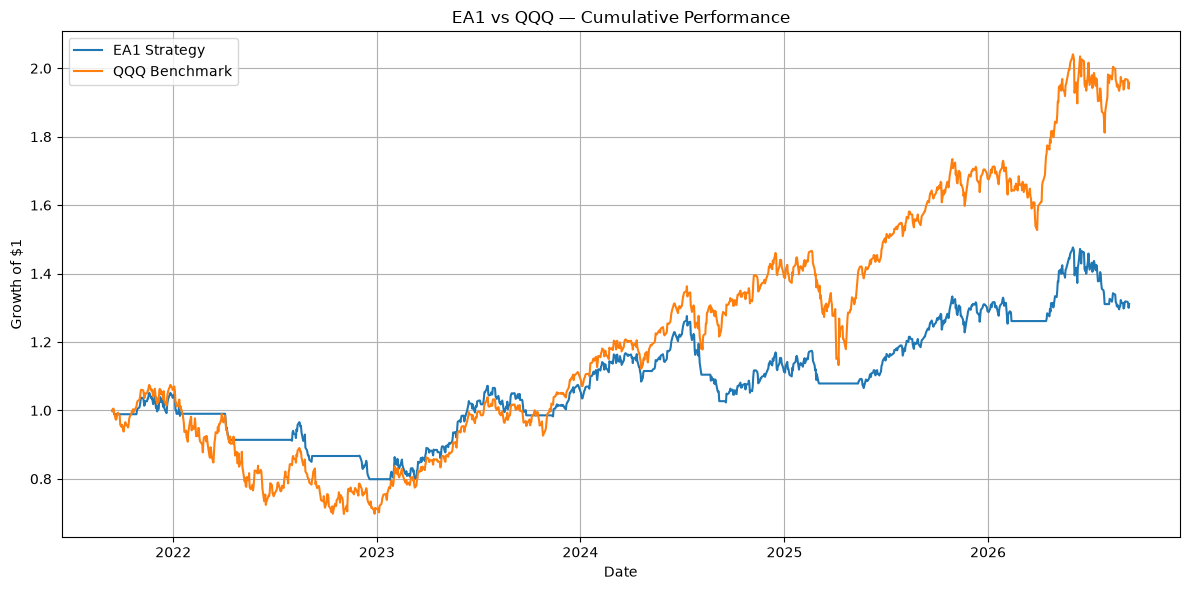

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(df.index, df["Cumulative Return"], label="EA1 Strategy")
plt.plot(df.index, df["Benchmark Return"], label="QQQ Benchmark")

plt.title("EA1 vs QQQ — Cumulative Performance")
plt.xlabel("Date")
plt.ylabel("Growth of $1")

plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig("EA1_vs_QQQ_cumulative_performance.png", dpi=300, bbox_inches="tight")

plt.show()

In [14]:
df[["Market Returns", "Strategy Returns", "Cumulative Return", "Benchmark Return"]].tail()

Price,Market Returns,Strategy Returns,Cumulative Return,Benchmark Return
Ticker,,,,
Date,,,,
2026-09-04,0.001798,0.001798,1.318546,1.968544
2026-09-08,-0.000835,-0.000835,1.317446,1.966901
2026-09-09,-0.002854,-0.002854,1.313686,1.961288
2026-09-10,-0.010638,-0.010638,1.299712,1.940424
2026-09-11,0.008734,0.008734,1.311064,1.957373


In [15]:
years = (df.index[-1] - df.index[0]).days / 365.25

cagr = (df["Cumulative Return"].iloc[-1] ** (1 / years)) - 1

print("Years:", round(years, 2))
print("CAGR:", round(cagr * 100, 2), "%")

Years: 4.99
CAGR: 5.57 %


In [16]:
daily_volatility = df["Strategy Returns"].std()
annualized_volatility = daily_volatility * np.sqrt(252)

print("Daily Volatility:", round(daily_volatility * 100, 2), "%")
print("Annualized Volatility:", round(annualized_volatility * 100, 2), "%")

Daily Volatility: 0.95 %
Annualized Volatility: 15.05 %


In [17]:
peak = df["Cumulative Return"].cummax()

drawdown = (df["Cumulative Return"] - peak) / peak

max_drawdown = drawdown.min()

print("Maximum Drawdown:", round(max_drawdown * 100, 2), "%")

Maximum Drawdown: -24.18 %


In [18]:
mean_daily_return = df["Strategy Returns"].mean()
daily_volatility = df["Strategy Returns"].std()

sharpe_ratio = (mean_daily_return / daily_volatility) * np.sqrt(252)

print("Mean Daily Return:", round(mean_daily_return * 100, 4), "%")
print("Daily Volatility:", round(daily_volatility * 100, 2), "%")
print("Sharpe Ratio:", round(sharpe_ratio, 2))

Mean Daily Return: 0.0261 %
Daily Volatility: 0.95 %
Sharpe Ratio: 0.44


## Trade-Level Analysis

The purpose of this section is to investigate whether EA1's
positive performance is concentrated in a small number of trades.

We will examine:
- Trade return
- Winning vs losing trades
- Holding period
- Largest winners and losers

### Trade Accounting Convention

Trade events are identified using changes in the shifted position.

- Entry: Position changes from 0 to 1.
- Exit: Position changes from 1 to 0.
- Trade returns are calculated by compounding daily strategy returns.

Entry and exit dates represent position-state changes in the backtest,
not verified broker execution timestamps.

In [19]:
df["Position Change"] = df["Position"].diff()

df["Trade Event"] = np.select(
    [df["Position Change"] > 0, df["Position Change"] < 0],
    ["Entry", "Exit"],
    default="Holding"
)

df["Trade ID"] = np.where(
    df["Trade Event"] == "Entry",
    1,
    0
).cumsum()

df["Trade ID"] = df["Trade ID"].ffill()

In [20]:
df.loc[
    df["Trade Event"].isin(["Entry", "Exit"]),
    ["Trade ID", "Trade Event", "Position"]
]

Price,Trade ID,Trade Event,Position
Ticker,,,
Date,,,
2021-09-16,1,Entry,1.0
2021-09-20,1,Exit,0.0
2021-10-28,2,Entry,1.0
2022-01-18,2,Exit,0.0
2022-04-05,3,Entry,1.0
2022-04-12,3,Exit,0.0
2022-08-02,4,Entry,1.0
2022-09-08,4,Exit,0.0


In [21]:
# Identify completed trades
closed_trade_ids = df.loc[df["Trade Event"] == "Exit", "Trade ID"].unique()

# Calculate compounded returns for completed trades
trade_returns = (df[df["Trade ID"].isin(closed_trade_ids)].groupby("Trade ID")["Strategy Returns"].apply(lambda x: (1 + x).prod() - 1))

trade_returns

Trade ID
1    -0.011163
2     0.001304
3    -0.076929
4    -0.051702
5    -0.078280
6     0.233690
7     0.131510
8    -0.009670
9    -0.070073
10    0.050305
11    0.169121
12    0.039312
Name: Strategy Returns, dtype: float64

In [22]:
# Identify entries and exits
entries = (df.loc[df["Trade Event"] == "Entry", "Trade ID"].reset_index().rename(columns={"Date": "Entry Date"}))

exits = (df.loc[df["Trade Event"] == "Exit", "Trade ID"].reset_index().rename(columns={"Date": "Exit Date"}))

# Match completed trades
trade_table = entries.merge(exits, on="Trade ID", how="inner")

# Add compounded trade returns
trade_table["Trade Return"] = trade_table["Trade ID"].map(trade_returns)

# Validate results
assert len(trade_table) == len(closed_trade_ids)
assert trade_table["Trade Return"].notna().all()

trade_table

,Entry Date,Trade ID,Exit Date,Trade Return
0,2021-09-16,1,2021-09-20,-0.011163
1,2021-10-28,2,2022-01-18,0.001304
2,2022-04-05,3,2022-04-12,-0.076929
3,2022-08-02,4,2022-09-08,-0.051702
4,2022-12-01,5,2022-12-20,-0.078280
5,2023-01-25,6,2023-09-27,0.233690
6,2023-11-13,7,2024-04-25,0.131510
7,2024-05-08,8,2024-08-06,-0.009670
8,2024-08-22,9,2024-09-09,-0.070073
9,2024-09-17,10,2025-03-05,0.050305


In [23]:
trade_table["Win/Loss"] = np.where(
    trade_table["Trade Return"] > 0,
    "Win",
    "Loss"
)

trade_table

,Entry Date,Trade ID,Exit Date,Trade Return,Win/Loss
0,2021-09-16,1,2021-09-20,-0.011163,Loss
1,2021-10-28,2,2022-01-18,0.001304,Win
2,2022-04-05,3,2022-04-12,-0.076929,Loss
3,2022-08-02,4,2022-09-08,-0.051702,Loss
4,2022-12-01,5,2022-12-20,-0.078280,Loss
5,2023-01-25,6,2023-09-27,0.233690,Win
6,2023-11-13,7,2024-04-25,0.131510,Win
7,2024-05-08,8,2024-08-06,-0.009670,Loss
8,2024-08-22,9,2024-09-09,-0.070073,Loss
9,2024-09-17,10,2025-03-05,0.050305,Win


In [24]:
trade_table["Holding Period"] = (
    pd.to_datetime(trade_table["Exit Date"])
    - pd.to_datetime(trade_table["Entry Date"])
).dt.days

trade_table

,Entry Date,Trade ID,Exit Date,Trade Return,Win/Loss,Holding Period
0,2021-09-16,1,2021-09-20,-0.011163,Loss,4
1,2021-10-28,2,2022-01-18,0.001304,Win,82
2,2022-04-05,3,2022-04-12,-0.076929,Loss,7
3,2022-08-02,4,2022-09-08,-0.051702,Loss,37
4,2022-12-01,5,2022-12-20,-0.078280,Loss,19
5,2023-01-25,6,2023-09-27,0.233690,Win,245
6,2023-11-13,7,2024-04-25,0.131510,Win,164
7,2024-05-08,8,2024-08-06,-0.009670,Loss,90
8,2024-08-22,9,2024-09-09,-0.070073,Loss,18
9,2024-09-17,10,2025-03-05,0.050305,Win,169


In [25]:
average_win_duration = trade_table.loc[
    trade_table["Win/Loss"] == "Win",
    "Holding Period"
].mean()

average_loss_duration = trade_table.loc[
    trade_table["Win/Loss"] == "Loss",
    "Holding Period"
].mean()

print("Average Winning Trade Duration:",
      round(average_win_duration, 1), "days")

print("Average Losing Trade Duration:",
      round(average_loss_duration, 1), "days")

Average Winning Trade Duration: 173.3 days
Average Losing Trade Duration: 29.2 days


In [26]:
# Identify the three largest winning trades
largest_winners = trade_table.nlargest(3, "Trade Return")

# Sum their individual returns
top_3_return_sum = largest_winners["Trade Return"].sum()

# Calculate the sum of the remaining trade returns
other_trades = trade_table.drop(index=largest_winners.index)
other_returns_sum = other_trades["Trade Return"].sum()

print("Top 3 Winners:", round(top_3_return_sum * 100, 2), "%")
print("Other Trades:", round(other_returns_sum * 100, 2), "%")

largest_winners

Top 3 Winners: 53.43 %
Other Trades: -20.69 %


,Entry Date,Trade ID,Exit Date,Trade Return,Win/Loss,Holding Period
5,2023-01-25,6,2023-09-27,0.233690,Win,245
10,2025-05-14,11,2026-02-13,0.169121,Win,275
6,2023-11-13,7,2024-04-25,0.131510,Win,164


In [27]:
win_count = (trade_table["Win/Loss"] == "Win").sum()
loss_count = (trade_table["Win/Loss"] == "Loss").sum()

average_win = trade_table.loc[
    trade_table["Win/Loss"] == "Win",
    "Trade Return"
].mean()

average_loss = trade_table.loc[
    trade_table["Win/Loss"] == "Loss",
    "Trade Return"
].mean()

print("Winning Trades:", win_count)
print("Losing Trades:", loss_count)
print("Win Rate:", round(win_count / len(trade_table) * 100, 2), "%")
print("Average Win:", round(average_win * 100, 2), "%")
print("Average Loss:", round(average_loss * 100, 2), "%")

Winning Trades: 6
Losing Trades: 6
Win Rate: 50.0 %
Average Win: 10.42 %
Average Loss: -4.96 %


In [28]:
# Average return per completed trade
expectancy = trade_table["Trade Return"].mean()

print("Trade Expectancy:", round(expectancy * 100, 2), "%")

Trade Expectancy: 2.73 %


In [29]:
days_in_market = (df["Position"] == 1).sum()
days_out_market = (df["Position"] == 0).sum()
total_days = days_in_market + days_out_market

print("Days in Market:", days_in_market)
print("Days Out of Market:", days_out_market)
print("Market Exposure:",
      round(days_in_market / total_days * 100, 2), "%")

Days in Market: 855
Days Out of Market: 399
Market Exposure: 68.18 %


In [30]:
yearly_returns = (
    df["Strategy Returns"]
    .groupby(df.index.year)
    .apply(lambda x: (1 + x).prod() - 1)
)

yearly_returns

Date
2021    0.036609
2022   -0.229354
2023    0.338556
2024    0.040642
2025    0.159055
2026    0.016511
Name: Strategy Returns, dtype: float64

In [31]:
# EA1 vs QQQ — Performance Comparison

strategy_returns = df["Strategy Returns"].squeeze()
market_returns = df["Market Returns"].squeeze()

strategy_equity = df["Cumulative Return"].squeeze()
benchmark_equity = df["Benchmark Return"].squeeze()

# Calculate performance metrics
def performance_summary(returns, equity):
    volatility = returns.std()

    return {"CAGR": equity.iloc[-1] ** (1 / years) - 1, "Annualized Volatility": volatility * np.sqrt(252),
        "Sharpe Ratio": returns.mean() / volatility * np.sqrt(252), "Maximum Drawdown": (equity / equity.cummax() - 1).min()}

# Compare both investments
comparison = pd.DataFrame({"EA1": performance_summary(strategy_returns, strategy_equity),
    "QQQ Buy & Hold": performance_summary(market_returns, benchmark_equity)}).T

# Display formatted results
comparison.style.format({"CAGR": "{:.2%}", "Annualized Volatility": "{:.2%}", "Sharpe Ratio": "{:.2f}", "Maximum Drawdown": "{:.2%}"})

,CAGR,Annualized Volatility,Sharpe Ratio,Maximum Drawdown
EA1,5.57%,15.05%,0.44,-24.18%
QQQ Buy & Hold,14.39%,23.00%,0.70,-35.12%


In [32]:
peak = df["Cumulative Return"].cummax()

drawdown = (
    df["Cumulative Return"] - peak
) / peak

max_drawdown_date = drawdown.idxmin()

print("Maximum Drawdown:",
      round(drawdown.min() * 100, 2), "%")

print("Maximum Drawdown Date:",
      max_drawdown_date)

Maximum Drawdown: -24.18 %
Maximum Drawdown Date: 2023-01-25 00:00:00


In [33]:
peak = df["Cumulative Return"].cummax()

drawdown = (
    df["Cumulative Return"] - peak
) / peak

max_dd_date = drawdown.idxmin()

recovery_date = df.loc[
    (df.index > max_dd_date) &
    (df["Cumulative Return"] >= peak.loc[max_dd_date])
].index.min()

print("Maximum Drawdown Date:", max_dd_date)
print("Recovery Date:", recovery_date)

if pd.notna(recovery_date):
    recovery_days = (recovery_date - max_dd_date).days
    print("Recovery Time:", recovery_days, "days")
else:
    print("Drawdown has not fully recovered.")

Maximum Drawdown Date: 2023-01-25 00:00:00
Recovery Date: 2023-07-13 00:00:00
Recovery Time: 169 days


### Benchmark Comparison and Interpretation

EA1 generated positive historical returns but underperformed a passive QQQ investment during the research period.

The strategy achieved a CAGR of 5.57%, compared with approximately 14.39% for QQQ buy-and-hold.

However, EA1 experienced lower annualized volatility (15.05% versus 23.00%) and a smaller maximum drawdown (-24.18% versus -35.12%).

These results suggest that the strategy reduced historical market risk partly by maintaining lower market exposure.

EA1 was invested approximately 68% of the time. While remaining outside the market may have reduced losses during declining periods, it also created opportunities to miss market recoveries and sustained upward movements.

Furthermore, EMA crossovers are lagging signals. They identify changes in trends after those changes have begun, potentially reducing participation in profitable market movements.

These mechanisms are consistent with the observed results, although their individual contributions were not quantified.

Despite its lower volatility, EA1 produced a weaker Sharpe ratio (0.44 versus 0.70), indicating that its reduction in risk did not translate into superior risk-adjusted returns.

### Research Limitations

This experiment has several important limitations:

* Only 12 completed trades were analyzed.
* The research focused on one instrument and one historical period.
* Transaction costs and slippage were excluded.
* No independent out-of-sample validation was performed.
* Trade execution was modeled using simplified daily closing-price assumptions.

Consequently, these results should not be interpreted as evidence of a statistically validated trading edge.

### Final Assessment

EA1 demonstrated the asymmetric trade-return characteristics of a trend-following strategy, with relatively few large winners compensating for multiple smaller losses.

However, it did not outperform QQQ in absolute or risk-adjusted historical returns.

The experiment illustrates that reducing volatility and drawdown does not necessarily improve investment efficiency.

Rather than optimizing the original EMA parameters to improve historical performance, EA1 v0.1 was preserved as an exploratory research baseline.

**Research Status: Frozen — Exploratory Backtesting Study.**


The analysis of 12 completed trades produced a 50% win rate and an average return of approximately 2.73% per completed trade. The three largest winning trades generated a combined +53.43 percentage points when individual returns were summed, while the remaining nine trades collectively generated −20.69 percentage points. These figures are not compounded portfolio returns, but they illustrate EA1's substantial dependence on a small number of successful trends.
